In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
np.set_printoptions(suppress=True)
from sklearn.preprocessing import MinMaxScaler

In [2]:
technique_indicatorttm = np.load('******_matrix_ttm.npy',allow_pickle=True)
technique_indicatorpbr = np.load('******_matrix_pbr.npy',allow_pickle=True)
technique_indicatorps = np.load('******_matrix_ps.npy',allow_pickle=True)
technique_indicatorpcf = np.load('******_matrix_pcf.npy',allow_pickle=True)
sample_data = np.concatenate((technique_indicatorttm,technique_indicatorpbr,technique_indicatorps,technique_indicatorpcf),axis=2)
sample_data[pd.isna(sample_data)] = 5
sample_data.shape

(1215, 15, 12)

In [3]:
index=pd.read_csv('******close.csv',index_col=0)
index[pd.isna(index)] = 5
index_scaler = MinMaxScaler(feature_range=(-1, 1))
index_dataset = index_scaler.fit_transform(index)
index_dataset.shape

(1215, 15)

In [4]:
p=5
Label_data_2 = index_dataset[p-1:,:]
Label_data_2.shape

(1211, 15)

In [5]:
#input 部分
input_data = sample_data[:,:,:]
input_data.shape

(1215, 15, 12)

In [6]:
input_data_final = np.zeros((input_data.shape[0]+1-p,p,input_data.shape[1],input_data.shape[2]))
input_data_final.shape


(1211, 5, 15, 12)

In [7]:
for i in range(input_data.shape[0]+1-p):
    one_line = []
    for j in range(p):
        one_line.append(input_data[i+j])
        
    input_data_final[i] = np.array(one_line)
    

In [8]:
#input 部分
input_data_final.shape

(1211, 5, 15, 12)

In [9]:
N=15
M=1211
P=5
F=12
TEST_SIZE = 0.3 # the test and val size of dataset
RANDOM_STATE = 4

In [10]:
T = np.load('******shareholding_relation_adjacent_matrix_tongyi.npy')
I= np.load('******bankgraph/bank_qa_graph.npy')
S=np.load('******bankgraph/bankvolume_kendall.npy')


In [11]:
Fixed_Matrices = [S,I,T]

In [12]:
samples = input_data_final#np.random.normal(size=(M, P, N, F))
labels = Label_data_2#np.random.normal(size=(M, N))

In [13]:
x_train, x_test, y_train, y_test = train_test_split(samples, labels, test_size=TEST_SIZE, random_state=RANDOM_STATE)
x_test, x_val, y_test, y_val = train_test_split(x_test, y_test, test_size=0.33, random_state=RANDOM_STATE)
print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)
print(x_val.shape, y_val.shape)
x_train = tf.constant(x_train,dtype=tf.float32)
y_train = tf.constant(y_train,dtype=tf.float32)
x_test = tf.constant(x_test,dtype=tf.float32)
y_test = tf.constant(y_test,dtype=tf.float32)
x_val = tf.constant(x_val,dtype=tf.float32)
y_val= tf.constant(y_val,dtype=tf.float32)

(847, 5, 15, 12) (847, 15)
(243, 5, 15, 12) (243, 15)
(121, 5, 15, 12) (121, 15)


In [14]:
from keras.models import Sequential
from keras.layers import Dense, LSTM, Dropout, GRU, Bidirectional
from keras.optimizers import SGD
from keras.callbacks import History
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, TensorBoard

In [15]:
import tensorflow as tf

class GATGRU(tf.keras.Model):
    def __init__(self, N, F, Units_GAT, Units_GRU, Units_FC,
                 Fixed_Matrices, Matrix_Weights, Is_Dyn,
                 kernel_initializer='glorot_uniform',
                 bias_initializer='zeros'):
        super(GATGRU, self).__init__()
        # Number of Nodes
        self.N = N
        # the number of input features
        self.F = F
        # pre-defined matrices: shape=[(N,N),(N,N),(N,N)]
        self.mat = Fixed_Matrices
        # Dynamic Matrix:shape=(N,N)
        #self.dyn = self.add_weight(name='w_Dynamic', shape=(self.N, self.N),
                                 #initializer=tf.keras.initializers.get(kernel_initializer),
                                 #trainable=True)

        
        if Is_Dyn:
            self.mats = self.dyn
        else:
            self.mats = self.add_weight(name='w_Matrices', shape=(self.N, self.N),
                                        initializer=tf.keras.initializers.get(kernel_initializer),
                                        trainable=True)
            for i in range(len(Matrix_Weights)):
                coe = tf.Variable(1.0,trainable=True)
                self.mats = self.mats + Matrix_Weights[i]*self.mat[i]*coe
        
        # GAT_Weights
        self.units_gat = Units_GAT
        self.w_gat = []
        self.a_gat = []
        self.b_gat = []
        pre = self.F
        for i in range(len(self.units_gat)):
            aft = self.units_gat[i]
            w = self.add_weight(name='w_GAT', shape=(pre, aft),
                                initializer=tf.keras.initializers.get(kernel_initializer),
                                trainable=True)
            self.w_gat.append(w)
            a = self.add_weight(name='a_GAT', shape=(2 * aft, 1),
                                initializer=tf.keras.initializers.get(kernel_initializer),
                                trainable=True)
            self.a_gat.append(a)
            b = self.add_weight(name='b_GAT', shape=(aft,),
                                initializer=tf.keras.initializers.get(bias_initializer),
                                trainable=True)
            self.b_gat.append(b)
            pre = aft
        # GRU_Weights
        self.units_gru = Units_GRU
        self.w_gru = []
        self.b_gru = []
        # the number of output features of Multi-GAT
        C = self.units_gat[-1]
        F = self.F
        for i in range(len(self.units_gru)-1):
            H = self.units_gru[i]
            pre = F+C+H
            aft = H
            for j in range(3):
                w = self.add_weight(name='w_GRU', shape=(pre,aft),
                                    initializer=tf.keras.initializers.get(kernel_initializer),
                                    trainable=True)
                self.w_gru.append(w)
                b = self.add_weight(name='b_GRU', shape=(aft,),
                                    initializer=tf.keras.initializers.get(bias_initializer),
                                    trainable=True)
                self.b_gru.append(b)
            F = aft
        # the last layer weights
        H = self.units_gru[-2]
        G = self.units_gru[-1]
        w = self.add_weight(name='w_GRU', shape=(H,G),
                            initializer=tf.keras.initializers.get(kernel_initializer),
                            trainable=True)
        
        self.w_gru.append(w)
        b = self.add_weight(name='b_GRU', shape=(G,),
                                 initializer=tf.keras.initializers.get(bias_initializer),
                                 trainable=True)
        self.b_gru.append(b)
        
        # FC_weights
        self.units_fc = Units_FC
        self.w_fc = []
        self.b_fc = []
        pre = G
        for i in range(len(self.units_fc)):
            aft = self.units_fc[i]
            w = self.add_weight(name='w_FC', shape=(pre,aft),
                                initializer=tf.keras.initializers.get(kernel_initializer),
                                trainable=True)
            self.w_fc.append(w)
            b = self.add_weight(name='b_FC', shape=(aft,),
                                initializer=tf.keras.initializers.get(bias_initializer),
                                trainable=True)
            self.b_fc.append(b)
            pre = aft
    
    def Multi_GAT(self, inputs):
        '''
        inputs:shape=(None,P,N,F)
        x_gat:shape=(None,P,N,C)
        '''
        P = inputs.shape[1]
        x_gat = []
        for t in range(P):
            # (None, P, N, F) =>(None, N, F)
            xt_gat = inputs[:,t,:,:]
            
            # (N,N)*(None, N, F)*(F,C)=> (None, N, C)
            for i in range(len(self.units_gat)):
                xt_gat = self.gat_layer(xt_gat, self.w_gat[i], self.a_gat[i], self.b_gat[i])
            x_gat.append(xt_gat)
        # (None,P,N,C)
        x_gat = tf.stack(x_gat, axis=1)
        return x_gat

    def gat_layer(self, inputs, w, a, b):
        '''
        GAT layer implementation
        inputs: (None, N, F)
        w: (F, C)
        a: (2*C, 1)
        b: (C,)
        '''
        h = tf.matmul(inputs, w)  # (None, N, C)
        N = h.shape[1]
        a_input = tf.concat([tf.repeat(h, repeats=N, axis=1), tf.tile(h, [1, N, 1])], axis=-1)
        e = tf.nn.leaky_relu(tf.matmul(a_input, a))  # (None, N*N, 1)
        e = tf.reshape(e, [-1, N, N])  # (None, N, N)
        attention = tf.nn.softmax(e, axis=2)  # (None, N, N)
        h_prime = tf.matmul(attention, h)  # (None, N, C)
        h_prime = h_prime + b
        return tf.nn.elu(h_prime)
    
    def GRU(self, x, x_gat):
        '''
        x:shape=(None,P,N,F)
        x_gat:shape=(None,N,C)
        x_gru:shape=(None,N,G)
        '''
        # initialize the hidden state in each gru layer
        h_gru = []
        # (None, P, N, F)=>(None, N, F)*(F,H)=> (None, N, H)
        for i in range(len(self.units_gru)-1):
            H = self.units_gru[i]
            h = tf.zeros_like(x[:,0,:,:], dtype=tf.float32) @ tf.zeros([F, H])
            h_gru.append(h)
        
        # all gru layers at each time step
        for t in range(P):
            # (None, P, N, C) =>(None, N, C)
            xt_gat = x_gat[:,t,:,:]
            # (None, P, N, F) =>(None, N, F)
            xt = x[:,t,:,:]

            # the i_th layer
            for i in range(len(h_gru)):
                #(None, N, H)
                ht_1 = h_gru[i]
                #(None, N, F)+(None, N, C)+(None, N, H)=> (None, N, C+F+H)
                x_tgh = tf.concat([xt,xt_gat,ht_1], axis=2)
                #(None, N, C+F+H)=> (None, N, H)
                ut = tf.nn.sigmoid(x_tgh @ self.w_gru[3*i+0] + self.b_gru[3*i+0])
                rt =  tf.nn.sigmoid(x_tgh @ self.w_gru[3*i+1] + self.b_gru[3*i+1])
                
                # (None, N, C+F+H)
                x_tghr = tf.concat([xt, xt_gat, tf.multiply(rt, ht_1)], axis=2)
                
                # (None, N, H)
                ct = tf.nn.tanh(x_tghr @ self.w_gru[3*i+2] + self.b_gru[3*i+2])
                # (None, N, H)
                ht = tf.multiply(ut, ht_1) + tf.multiply((1-ut), ct)
                # (None, N, H)
                xt = ht
                # (None, N, H)
                h_gru[i]=ht
        # the last layer
        x_gru = tf.nn.sigmoid(ht @ self.w_gru[-1] + self.b_gru[-1])
        return x_gru
    
    def FC(self, x_gru):
        '''
        x_gru:shape=(None, N, G)
        outputs:shape=(None,N,1)
        '''
        x = x_gru
        for i in range(len(self.w_fc)):
            x = x @ self.w_fc[i] + self.b_fc[i]
            x = tf.nn.sigmoid(x)
        # (None, N)
        x_fc = tf.squeeze(x, axis=-1)
        return x_fc

    def build(self, input_shape):
        super().build(input_shape)
        
    def call(self, inputs):
        '''
        inputs:shape=(None,P,N,F)
        x_fc:shape=(None,N)
        '''
        # (None,P,N,C)
        x_gat = self.Multi_GAT(inputs)
        # (None,N,G)
        x_gru = self.GRU(inputs, x_gat)
        # (None,N)
        x_fc = self.FC(x_gru)
        return x_fc


In [16]:
Units_GAT = [16,32,64]
Units_GRU = [16,32]
Units_FC = [1]
Matrix_Weights = [1,1,1]
Is_Dyn=False
    
model = GATGRU(N, F, Units_GAT, Units_GRU, Units_FC, Fixed_Matrices, Matrix_Weights,Is_Dyn)
model.build(input_shape=(None, P, N, F))
model.summary()
model.compile(loss='binary_crossentropy',optimizer='SGD',metrics=[tf.keras.metrics.BinaryAccuracy()])
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath = '******GATGRU',
    monitor ='val_binary_accuracy',
    save_weights_only = True,
    save_best_only = True)

Model: "gatgru"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
Total params: 8,129
Trainable params: 8,129
Non-trainable params: 0
_________________________________________________________________


In [17]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# 超参数
Epochs = 50
Batch_size = 32

# 初始化
history_list = []

# 训练 8 次模型
for run in range(8):
    print(f"\n========== Training Run {run+1}/8 ==========")
    
    # 回调函数
    model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=f'******GATGRU_run{run+1}',
        monitor='val_loss',
        save_best_only=True,
        save_weights_only=True,
        verbose=0
    )
    
    tb = tf.keras.callbacks.TensorBoard(log_dir=f"******GATGRU/run{run+1}")
    
    # 模型重新初始化（如有自定义模型需显式重建）
    model = GATGRU(N, F, Units_GAT,  Units_GRU, Units_FC, Fixed_Matrices, Matrix_Weights, Is_Dyn)
    model.build(input_shape=(None, P, N, F))
    model.compile(loss='categorical_crossentropy', optimizer='SGD', metrics=[tf.keras.metrics.BinaryAccuracy()])

    # 拟合
    history = model.fit(
        x_train, y_train,
        batch_size=Batch_size,
        epochs=Epochs,
        callbacks=[model_checkpoint, tb],
        validation_data=(x_val, y_val),
        verbose=1
    )
    history_list.append(history)



========== Training Run 1/8 ==========
Epoch 1/50
27/27 [==============================] - 28s 259ms/step - loss: -9.5436 - binary_accuracy: 3.9355e-04 - val_loss: -9.9716 - val_binary_accuracy: 0.0000e+00
Epoch 2/50
27/27 [==============================] - 3s 118ms/step - loss: -9.6992 - binary_accuracy: 2.3613e-04 - val_loss: -10.2609 - val_binary_accuracy: 0.0000e+00
Epoch 3/50
27/27 [==============================] - 3s 102ms/step - loss: -10.2668 - binary_accuracy: 2.3613e-04 - val_loss: -11.7421 - val_binary_accuracy: 0.0000e+00
Epoch 4/50
27/27 [==============================] - 3s 103ms/step - loss: -17.8483 - binary_accuracy: 2.3613e-04 - val_loss: -33.2534 - val_binary_accuracy: 0.0000e+00
Epoch 5/50
27/27 [==============================] - 3s 95ms/step - loss: -46.4579 - binary_accuracy: 2.3613e-04 - val_loss: -51.4237 - val_binary_accuracy: 0.0000e+00
Epoch 6/50
27/27 [==============================] - 2s 86ms/step - loss: -51.3752 - binary_accuracy: 2.3613e-04 - val_loss:

27/27 [==============================] - 4s 146ms/step - loss: -64.2303 - binary_accuracy: 2.3613e-04 - val_loss: -67.3286 - val_binary_accuracy: 0.0000e+00
Epoch 17/50
27/27 [==============================] - 4s 143ms/step - loss: -64.8393 - binary_accuracy: 2.3613e-04 - val_loss: -67.2766 - val_binary_accuracy: 0.0000e+00
Epoch 18/50
27/27 [==============================] - 4s 134ms/step - loss: -64.9362 - binary_accuracy: 2.3613e-04 - val_loss: -67.1174 - val_binary_accuracy: 0.0000e+00
Epoch 19/50
27/27 [==============================] - 4s 144ms/step - loss: -65.0521 - binary_accuracy: 2.3613e-04 - val_loss: -67.7859 - val_binary_accuracy: 0.0000e+00
Epoch 20/50
27/27 [==============================] - 5s 174ms/step - loss: -65.1068 - binary_accuracy: 2.3613e-04 - val_loss: -67.7907 - val_binary_accuracy: 0.0000e+00
Epoch 21/50
27/27 [==============================] - 4s 139ms/step - loss: -65.3116 - binary_accuracy: 2.3613e-04 - val_loss: -67.8765 - val_binary_accuracy: 0.0000e+0

IOPub message rate exceeded.
The notebook server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--NotebookApp.iopub_msg_rate_limit`.

Current values:
NotebookApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
NotebookApp.rate_limit_window=3.0 (secs)



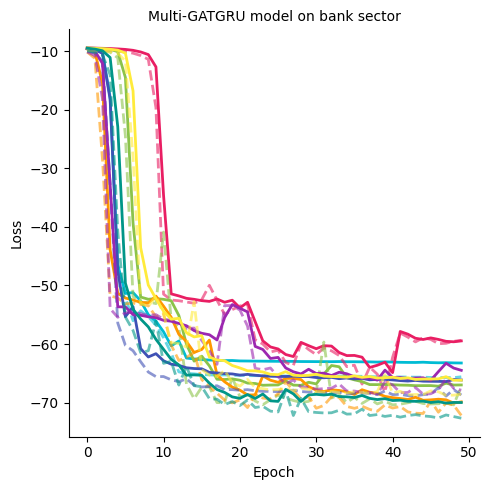

In [18]:
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
plt.style.use('default')

colors = ['#00BCD4', '#E91E63', '#8BC34A', '#FF9800', '#3F51B5', '#9C27B0', '#FFEB3B', '#009688']

plt.figure(figsize=(5, 5))
for i, history in enumerate(history_list):
    color = colors[i % len(colors)]
    plt.plot(history.history['loss'], label=f'Run {i+1} - Train', color=color, linewidth=2)
    plt.plot(history.history['val_loss'], '--', label=f'Run {i+1} - Val', color=color, alpha=0.6, linewidth=2)
#plt.text(0.5, -0.25, '(a)Bank sector', transform=ax.transAxes, fontsize=10, fontweight='bold', ha='center')
plt.title('Multi-GATGRU model on bank sector', fontsize=10)
plt.xlabel('Epoch')
plt.ylabel('Loss')
# 去除上右边框
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
#plt.legend(loc='upper right', fontsize=10)
#plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('******gatgru_loss_curve.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()


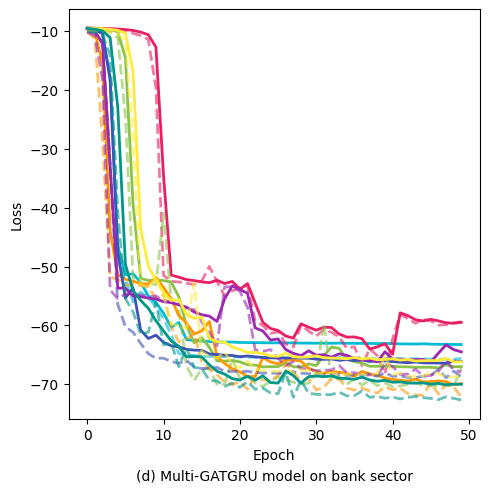

In [19]:
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
plt.style.use('default')

colors = ['#00BCD4', '#E91E63', '#8BC34A', '#FF9800', '#3F51B5', '#9C27B0', '#FFEB3B', '#009688']
fig, ax = plt.subplots(figsize=(5, 5))
#plt.figure(figsize=(5, 5))
for i, history in enumerate(history_list):
    color = colors[i % len(colors)]
    plt.plot(history.history['loss'], label=f'Run {i+1} - Train', color=color, linewidth=2)
    plt.plot(history.history['val_loss'], '--', label=f'Run {i+1} - Val', color=color, alpha=0.6, linewidth=2)

#plt.title('Multi-GATGRU Model on Bank sector', fontsize=10)
plt.xlabel('Epoch')
plt.ylabel('Loss')

#plt.legend(loc='upper right', fontsize=10)
#plt.grid(True, linestyle='--', alpha=0.3)
plt.text(0.5, -0.15, '(d) Multi-GATGRU model on bank sector', transform=ax.transAxes, fontsize=10, ha='center')
plt.tight_layout()
plt.savefig('******gatgru_loss_curve2.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

8/8 [==============================] - 4s 38ms/step


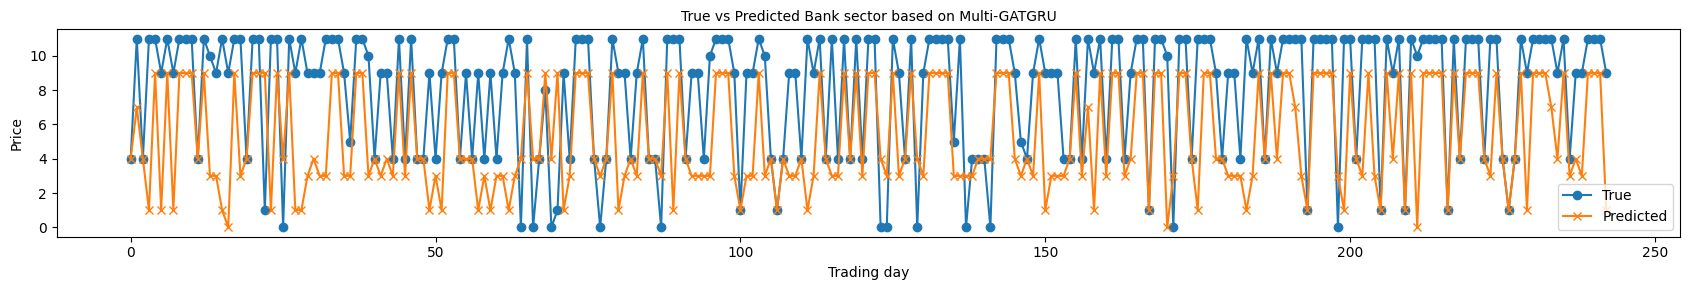

In [20]:
# 使用最后一次最优模型
model.load_weights('******GATGRU_run8')

# 预测
y_pred = model.predict(x_test)

# 分类任务处理：若为 one-hot 编码，取最大值索引；否则为二分类阈值判断
if y_pred.shape[-1] > 1:
    y_pred_class = np.argmax(y_pred, axis=-1)
    y_true_class = np.argmax(y_test, axis=-1)
else:
    y_pred_class = (y_pred > 0.5).astype(int)
    y_true_class = y_test

# 绘制对比图
plt.figure(figsize=(17, 3))
plt.plot(y_true_class[:300], label='True', marker='o')
plt.plot(y_pred_class[:300], label='Predicted', marker='x')
plt.title('True vs Predicted Bank sector based on Multi-GATGRU', fontsize=10)
plt.xlabel('Trading day')
plt.ylabel('Price')
plt.legend()
#plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('******gatgru_pred_vs_true.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()


In [22]:
y_pred1 = pd.DataFrame(y_pred, columns=['PAD', 'SPDB', 'HXB', 'CMBC', 'CMB', 'CIB', 'ABC', 'BOCOM', 'ICBC','PSBC', 'CEB', 'CZB', 'CCB', 'BOC', 'ECITIC'])
y_pred1.to_csv('******gatgrupredict.csv')
y_pred2 = pd.DataFrame(y_pred_class, columns=['bankgatgru'])
y_pred2.to_csv('******gatgrupredict2.csv')